In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
def to_count(s):
    return pd.to_numeric(s.replace('-', 0), errors='raise').astype(int)

In [3]:
df_28_9= pd.read_excel('../data/raw/fz28_2026_09.xlsx', header=None, sheet_name="FZ 28.9")

regions = df_28_9.iloc[31:48, 1]
total_registrations_bundesland = to_count(df_28_9.iloc[31:48, 2])
electric_drive_registrations_bundesland = to_count(df_28_9.iloc[31:48, 5])
bev_registrations_bundesland = to_count(df_28_9.iloc[31:48, 7])
fcev_registrations_bundesland = to_count(df_28_9.iloc[31:48, 8])
phev_registrations_bundesland = to_count(df_28_9.iloc[31:48, 9])

assert df_28_9.iloc[30, 1].strip().lower() == 'januar - september 2026'
assert total_registrations_bundesland.sum() == df_28_9.iloc[30,2]
assert electric_drive_registrations_bundesland.sum() == df_28_9.iloc[30,5]
assert bev_registrations_bundesland.sum() == df_28_9.iloc[30,7]
assert phev_registrations_bundesland.sum() == df_28_9.iloc[30,9]

assert (electric_drive_registrations_bundesland ==
           bev_registrations_bundesland + phev_registrations_bundesland + fcev_registrations_bundesland).all()

regional = pd.DataFrame({
    'bundesland': regions.str.strip(),
    'total_ytd26': total_registrations_bundesland,
    'electric_ytd26': electric_drive_registrations_bundesland,
    'bev_ytd26': bev_registrations_bundesland,
    'phev_ytd26': phev_registrations_bundesland
}).reset_index(drop=True)

regional = regional[regional['bundesland'] != 'Sonstige'].reset_index(drop=True)
assert len(regional) == 16

regional['bev_share_ytd26'] = regional['bev_ytd26'] / regional['total_ytd26'] * 100
regional['phev_share_ytd26'] = regional['phev_ytd26'] / regional['total_ytd26'] * 100
regional['bev_phev_ratio_ytd26'] = regional['bev_ytd26'] / regional['phev_ytd26']

national_total = df_28_9.iloc[30, 2]

national_bev_share = df_28_9.iloc[30,7] / national_total * 100
national_phev_share = df_28_9.iloc[30,9] / national_total * 100
national_bev_phev_ratio = df_28_9.iloc[30,7] / df_28_9.iloc[30,9]
print(national_bev_share, national_phev_share)

regional['bev_share_vs_national_pp'] = regional['bev_share_ytd26'] - national_bev_share
regional['phev_share_vs_national_pp'] = regional['phev_share_ytd26'] - national_phev_share
regional['bev_phev_ratio_vs_national'] = regional['bev_phev_ratio_ytd26'] - national_bev_phev_ratio

display(regional.sort_values(by='bev_share_ytd26', ascending=False).round(2))

27.191670889972897 11.139131460195753


,bundesland,total_ytd26,electric_ytd26,bev_ytd26,phev_ytd26,bev_share_ytd26,phev_share_ytd26,bev_phev_ratio_ytd26,bev_share_vs_national_pp,phev_share_vs_national_pp,bev_phev_ratio_vs_national
10,Rheinland-Pfalz,85556,36699,28286,8413,33.06,9.83,3.36,5.87,-1.31,0.92
14,Schleswig-Holstein,59787,25289,19503,5786,32.62,9.68,3.37,5.43,-1.46,0.93
8,Niedersachsen,246132,100103,73285,26818,29.77,10.90,2.73,2.58,-0.24,0.29
0,Baden-Württemberg,305951,131655,90905,40749,29.71,13.32,2.23,2.52,2.18,-0.21
9,Nordrhein-Westfalen,443825,179349,130092,49256,29.31,11.10,2.64,2.12,-0.04,0.20
4,Bremen,12018,5069,3470,1599,28.87,13.31,2.17,1.68,2.17,-0.27
11,Saarland,23107,8574,6412,2161,27.75,9.35,2.97,0.56,-1.79,0.53
2,Berlin,41345,17120,11445,5673,27.68,13.72,2.02,0.49,2.58,-0.42
3,Brandenburg,37048,13559,9969,3590,26.91,9.69,2.78,-0.28,-1.45,0.34
1,Bayern,467237,170311,124289,46021,26.60,9.85,2.70,-0.59,-1.29,0.26


In [4]:
charging_stations = pd.read_parquet('../data/processed/charging_stations_clean.parquet')

In [5]:
ports_by_bundesland = (
    charging_stations
    .groupby('Bundesland', as_index=False)['Anzahl Ladepunkte']
    .sum()
    .rename(columns={'Anzahl Ladepunkte': 'charging_ports'})
)

ports_by_bundesland['charging_ports'] = ports_by_bundesland['charging_ports'].astype(int)

In [6]:
ports = pd.concat(
    [charging_stations[['Bundesland', f'Steckertypen{i}']]
     .rename(columns={f'Steckertypen{i}': 'connectors'})
     for i in range(1, 7)],
    ignore_index=True
).dropna(subset=['connectors'])

ports['is_dc'] = ports['connectors'].str.contains('DC')
ports['is_ac_only'] = ports['connectors'].str.contains('AC') & ~ports['is_dc']

assert (ports['is_dc'] | ports['is_ac_only']).all()

In [7]:
assert len(ports) == charging_stations['Anzahl Ladepunkte'].sum()

In [8]:
port_types_by_bundesland = (
    ports
    .groupby('Bundesland', as_index=False)[['is_dc', 'is_ac_only']]
    .sum()
    .rename(columns={'is_dc': 'dc_ports', 'is_ac_only': 'ac_only_ports'})
)

In [9]:
infrastructure = ports_by_bundesland.merge(
    port_types_by_bundesland,
    on='Bundesland',
    validate='one_to_one'
)

assert len(infrastructure) == 16
assert (infrastructure['charging_ports'] == infrastructure['dc_ports'] + infrastructure['ac_only_ports']).all()

infrastructure['dc_port_share'] = (
    infrastructure['dc_ports'] / (infrastructure['dc_ports'] + infrastructure['ac_only_ports']) * 100
)

display(infrastructure.round(2))

,Bundesland,charging_ports,dc_ports,ac_only_ports,dc_port_share
0,Baden-Württemberg,20653,2857,17796,13.83
1,Bayern,22500,4298,18202,19.10
2,Berlin,4432,589,3843,13.29
3,Brandenburg,2661,700,1961,26.31
4,Bremen,854,116,738,13.58
5,Hamburg,2554,443,2111,17.35
6,Hessen,8660,1557,7103,17.98
7,Mecklenburg-Vorpommern,1643,364,1279,22.15
8,Niedersachsen,11828,2622,9206,22.17
9,Nordrhein-Westfalen,22882,4416,18466,19.30


In [10]:
population = pd.read_excel('../data/raw/12411-0021_de.xlsx', header=None)

name_cols = list(range(1, 47, 3))
assert (population.iloc[4, [c + 2 for c in name_cols]] == 'Insgesamt').all()

population_final = pd.DataFrame({
    'bundesland': [population.iloc[3, c].strip() for c in name_cols],
    'population': pd.to_numeric(population.iloc[24, [c + 2 for c in name_cols]]).to_numpy()
})

population_final.sort_values(by='population',ascending=False)
print(population.iloc[3:6, 0:7])
print(population.iloc[24, 0])

                           0                  1         2          3         4         5          6
3  Stichtag zum Quartalsende  Baden-Württemberg       NaN        NaN    Bayern       NaN        NaN
4                        NaN           männlich  weiblich  Insgesamt  männlich  weiblich  Insgesamt
5                 30.09.2021            5525810   5597583   11123393   6532463   6644181   13176644
30.06.2026


/Users/cankale/miniforge3/envs/auto_env/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [11]:
assert len(population_final) == 16
assert set(population_final['bundesland']) == set(regional['bundesland'])
print(population_final['population'].sum())

83298787


In [12]:
population_final.to_parquet('../data/processed/population_by_bundesland.parquet', index=False)

In [13]:
area = pd.read_excel('../data/raw/11111-0001_de.xlsx')

rows = list(range(4, 20))

area_final = pd.DataFrame({
    'bundesland': [area.iloc[r, 0].strip() for r in rows],
    'area_in_sqkm': pd.to_numeric(area.iloc[rows , 1]).to_numpy()
})


insgesamt = area.iloc[20, 1]

assert np.isclose(area_final['area_in_sqkm'].sum(), insgesamt)

print(area.iloc[20, 0])
assert len(area_final) == 16
assert set(area_final['bundesland']) == set(regional['bundesland'])

Insgesamt


/Users/cankale/miniforge3/envs/auto_env/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [14]:
area_final.to_parquet('../data/processed/area_by_bundesland.parquet', index=False)

In [15]:
def key(s):
    return s.replace('-', '').replace('\n', '').replace(' ', '').lower()

In [16]:
fz2_3 = pd.read_excel('../data/raw/fz2_2026.xlsx', header=None, sheet_name='FZ 2.3')

lookup = {key(b): b for b in regional['bundesland']}
state_names = [lookup[key(n)] for n in fz2_3.iloc[7, 4:20]]


row = 89
assert fz2_3.iloc[row].astype(str).str.contains('PERSONENKRAFTWAGEN INSGESAMT').any()

state_stock = to_count(fz2_3.iloc[row, 4:20])
sonstige_stock = int(fz2_3.iloc[row, 20])
germany_stock = int(fz2_3.iloc[row, 21])

assert state_stock.sum() + sonstige_stock == germany_stock

car_stock = pd.DataFrame({
    'bundesland': state_names,
    'car_stock': state_stock.to_numpy()
})

assert len(car_stock) == 16
assert set(car_stock['bundesland']) == set(regional['bundesland'])


In [17]:
car_stock.to_parquet('../data/processed/car_stock_by_bundesland.parquet', index=False)

Merging all data

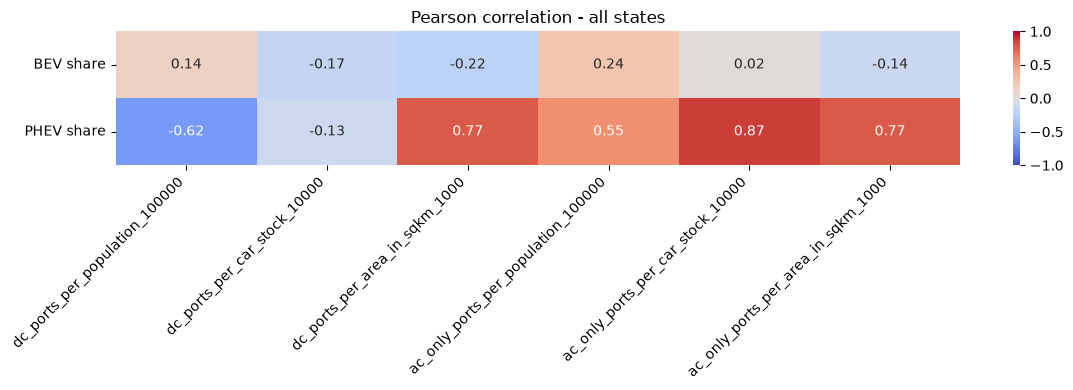

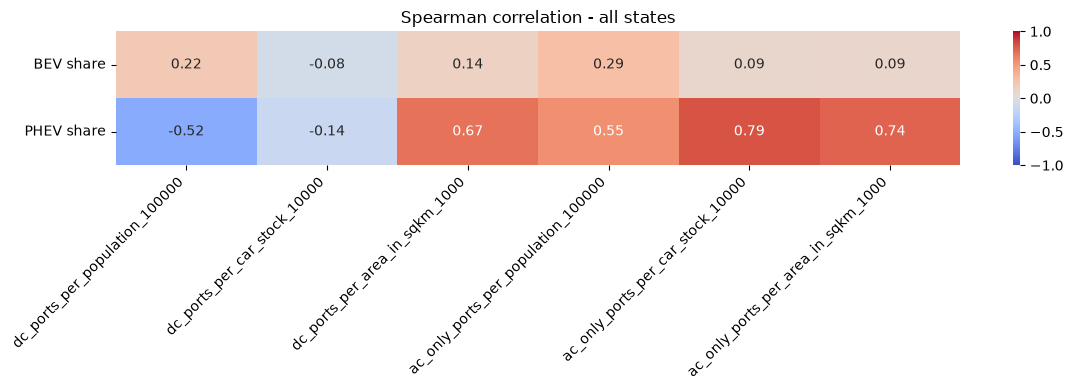

In [18]:
infrastructure = infrastructure.rename(columns={'Bundesland' : 'bundesland'})

tables = [regional,infrastructure, population_final, area_final, car_stock]

regional_merged = tables[0]

for df in tables[1:]:
    regional_merged = regional_merged.merge(
        df, how='outer', on='bundesland', validate='one_to_one', indicator=True
    )
    assert (regional_merged["_merge"] == "both").all()
    regional_merged = regional_merged.drop(columns="_merge")

assert len(regional_merged) == 16


normalization_cols = ['population', 'car_stock', 'area_in_sqkm']
target_cols = ['charging_ports', 'dc_ports', 'ac_only_ports']
multipliers = [100000, 10000, 1000]
for t in target_cols:
    for m, n in zip(multipliers, normalization_cols):
        regional_merged[f'{t}_per_{n}_{m}'] = regional_merged[t] / regional_merged[n] * m


regional_merged['population_density'] = regional_merged['population'] / regional_merged['area_in_sqkm']
regional_merged['log_population_density'] = np.log(regional_merged['population_density'])

def plot_correlation(df, methods=('pearson', 'spearman'), label='all states'):
    for me in methods:
        densities = df[density_cols]

        bev_phev_corr = pd.DataFrame({
            'BEV share': densities.corrwith(df['bev_share_ytd26'], method=me),
            'PHEV share': densities.corrwith(df['phev_share_ytd26'], method=me)
        }).T

        fig, ax = plt.subplots(figsize=(12, 4))

        ax = sns.heatmap(bev_phev_corr, annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt='.2f', ax=ax)
        ax.set_title(f"{me.capitalize()} correlation - {label}")
        ax.tick_params(axis='x', labelrotation=45)
        ax.tick_params(axis='y', labelrotation=0)

        plt.setp(ax.get_xticklabels(), ha='right')

        plt.tight_layout()
        plt.show()


density_cols = []
for t in target_cols[1:]:
    for m, n in zip(multipliers, normalization_cols):
        density_cols.append(f'{t}_per_{n}_{m}')


plot_correlation(df= regional_merged)

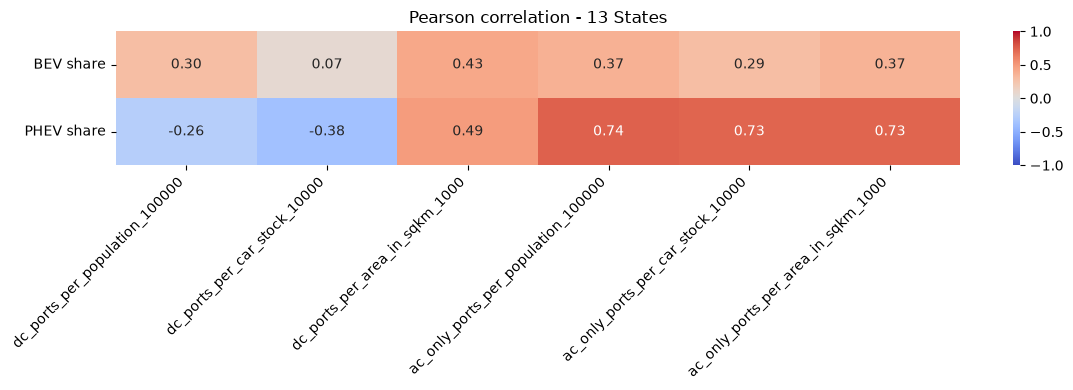

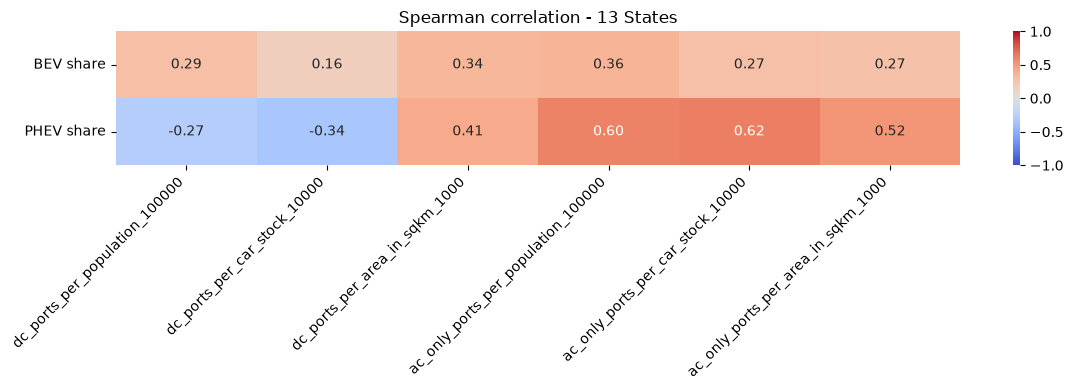

In [19]:
regional_merged_without_BHB = regional_merged[~regional_merged['bundesland'].isin(['Berlin', 'Hamburg', 'Bremen'])]

plot_correlation(regional_merged_without_BHB, label='13 States')

In [20]:
from scipy.stats import pearsonr, spearmanr


def p_test(df, method, density_cols):
    metrics = ['bev_share_ytd26', 'phev_share_ytd26']
    results = []
    if method == 'pearson':
        test = pearsonr
    elif method == 'spearman':
        test = spearmanr
    else:
        raise ValueError('Unidentified method passed!')
    
    for d in density_cols:
        for met in metrics:
            result = test(df[d], df[met])
            dictionary = {
                'share': met,
                'density': d,
                'method': method,
                'coef': result.statistic,
                'p_value': result.pvalue
                }
            results.append(dictionary)


    return pd.DataFrame(results)


result_dic = {
    'all states' : regional_merged,
    '13 states' : regional_merged_without_BHB
}
lst = []
for met in ['pearson', 'spearman']:
    for title, sample in result_dic.items():
        ergebnis = p_test(sample, method=met,density_cols=density_cols)
        ergebnis['sample'] = title
        ergebnis['n'] = len(sample)
        lst.append(ergebnis)

p_values = pd.concat(lst, ignore_index=True)
phev_results = p_values[p_values['share'].str.contains('phev')]

display(
    phev_results
    .sort_values(['density', 'method', 'sample'])
    .round({'coef': 2, 'p_value': 3})

)

,share,density,method,coef,p_value,sample,n
23,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,pearson,0.73,0.005,13 states,13
11,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,pearson,0.77,0.001,all states,16
47,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,spearman,0.52,0.067,13 states,13
35,phev_share_ytd26,ac_only_ports_per_area_in_sqkm_1000,spearman,0.74,0.001,all states,16
21,phev_share_ytd26,ac_only_ports_per_car_stock_10000,pearson,0.73,0.005,13 states,13
9,phev_share_ytd26,ac_only_ports_per_car_stock_10000,pearson,0.87,0.000,all states,16
45,phev_share_ytd26,ac_only_ports_per_car_stock_10000,spearman,0.62,0.024,13 states,13
33,phev_share_ytd26,ac_only_ports_per_car_stock_10000,spearman,0.79,0.000,all states,16
19,phev_share_ytd26,ac_only_ports_per_population_100000,pearson,0.74,0.004,13 states,13
7,phev_share_ytd26,ac_only_ports_per_population_100000,pearson,0.55,0.028,all states,16


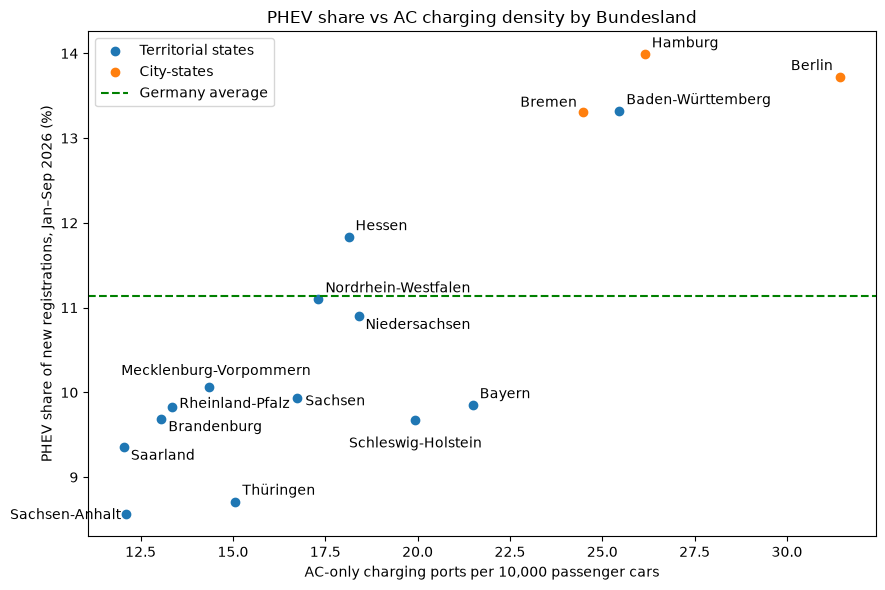

In [21]:
fig, ax = plt.subplots(figsize=(9,6))

city_mask = regional_merged['bundesland'].isin(['Berlin', 'Hamburg', 'Bremen'])

ax.scatter(regional_merged[~city_mask]['ac_only_ports_per_car_stock_10000'], y=regional_merged[~city_mask]['phev_share_ytd26'], label='Territorial states')
ax.scatter(regional_merged[city_mask]['ac_only_ports_per_car_stock_10000'], y=regional_merged[city_mask]['phev_share_ytd26'], label='City-states')
label_positions = {
    'Berlin': ((-5,5), 'right'),
    'Bremen': ((-4,4), 'right'),
    'Schleswig-Holstein': ((0,-20), 'center'),
    'Sachsen-Anhalt': ((-4,-4), 'right'),
    'Sachsen': ((6,-5), 'left'),
    'Rheinland-Pfalz': ((5,-1), 'left'),
    'Saarland': ((5,-9), 'left'),
    'Niedersachsen': ((5,-9), 'left'),
    'Mecklenburg-Vorpommern': ((5,9), 'center'),
    'Brandenburg': ((5,-9), 'left')
}
for _, row in regional_merged.iterrows():
    offset, ha = label_positions.get(row['bundesland'], ((5,5), 'left'))
    ax.annotate(row['bundesland'], 
                (row['ac_only_ports_per_car_stock_10000'], row['phev_share_ytd26']), 
                xytext=offset, ha=ha,
                textcoords='offset points')


ax.axhline(national_phev_share, linestyle='--', label='Germany average', color='green')
ax.set_xlabel("AC-only charging ports per 10,000 passenger cars")
ax.set_ylabel("PHEV share of new registrations, Jan–Sep 2026 (%)")
ax.set_title("PHEV share vs AC charging density by Bundesland")
ax.legend()
plt.tight_layout()
fig.savefig('../reports/figures/phev_vs_ac_density.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
display(
    regional_merged[['bundesland', 'population_density']].sort_values(by='population_density', ascending=False)
)

,bundesland,population_density
2,Berlin,4151.906589
5,Hamburg,2475.316850
4,Bremen,1682.090513
9,Nordrhein-Westfalen,526.029875
11,Saarland,390.395838
0,Baden-Württemberg,314.056706
6,Hessen,296.499277
12,Sachsen,217.213627
10,Rheinland-Pfalz,207.221084
1,Bayern,187.524540


In [29]:
density_lst = []
for met in ['pearson', 'spearman']:
    for title, sample in result_dic.items():
        ergebnis = p_test(sample, method=met,density_cols=['population_density', 'log_population_density'])
        ergebnis['sample'] = title
        ergebnis['n'] = len(sample)
        density_lst.append(ergebnis)

density_p_values = pd.concat(density_lst, ignore_index=True)

display(
    density_p_values.sort_values(by=['p_value', 'coef']).round({'coef': 2, 'p_value': 3})
)

,share,density,method,coef,p_value,sample,n
3,phev_share_ytd26,log_population_density,pearson,0.82,0.000,all states,16
1,phev_share_ytd26,population_density,pearson,0.74,0.001,all states,16
9,phev_share_ytd26,population_density,spearman,0.68,0.004,all states,16
11,phev_share_ytd26,log_population_density,spearman,0.68,0.004,all states,16
7,phev_share_ytd26,log_population_density,pearson,0.50,0.085,13 states,13
5,phev_share_ytd26,population_density,pearson,0.47,0.102,13 states,13
13,phev_share_ytd26,population_density,spearman,0.43,0.144,13 states,13
15,phev_share_ytd26,log_population_density,spearman,0.43,0.144,13 states,13
6,bev_share_ytd26,log_population_density,pearson,0.36,0.224,13 states,13
4,bev_share_ytd26,population_density,pearson,0.31,0.301,13 states,13


In [ ]:
density_ac_lst = []

for title, sample in result_dic.items():
    X = sample['log_population_density']
    Y= sample['ac_only_ports_per_car_stock_10000']
    for method in ['pearson', 'spearman']:
        result = pearsonr(X, Y) if method == 'pearson' else spearmanr(X, Y)
        density_ac_lst.append({
            'sample': title,
            'method': method, 
            'coef': result.statistic,
            'p_value': result.pvalue
        })

density_ac = pd.DataFrame(density_ac_lst)

display(
    density_ac
    .round({'coef': 2, 'p_value': 3})
)

,sample,method,coef,p_value
0,all states,pearson,0.79,0.000
1,all states,spearman,0.60,0.015
2,13 states,pearson,0.37,0.217
3,13 states,spearman,0.26,0.384


In [48]:
partial_lst = []


for title, sample in result_dic.items():
    x = sample['log_population_density']

    phev_slope, phev_intercept = np.polyfit(x, sample['phev_share_ytd26'], 1)
    phev_resid = sample['phev_share_ytd26'] - (phev_slope * x + phev_intercept)

    ac_slope, ac_intercept = np.polyfit(x, sample['ac_only_ports_per_car_stock_10000'], 1)
    ac_resid = sample['ac_only_ports_per_car_stock_10000'] - (ac_slope * x + ac_intercept)

    for method in ['pearson', 'spearman']:
        result_partial = pearsonr(phev_resid, ac_resid) if method == 'pearson' else spearmanr(phev_resid, ac_resid)
        partial_lst.append({
            'sample': title,
            'method': method,
            'coef': result_partial.statistic,
            'p_value': result_partial.pvalue
        })

partial = pd.DataFrame(partial_lst)
display(
    partial
    .round({'coef': 2, 'p_value': 3})
)

,sample,method,coef,p_value
0,all states,pearson,0.62,0.010
1,all states,spearman,0.47,0.068
2,13 states,pearson,0.68,0.011
3,13 states,spearman,0.59,0.035
